# Arbeitspaket (AP) 3 – Übung: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse — Musterlösung

### Hinweis

Dies ist eine **Übungsprüfung** im Stil von AP 2 (gleicher Aufbau, gleiches Bewertungsschema, neue Daten). Zeitbudget wie in der echten Prüfung: ca. **3 Stunden 45 Minuten**. Erlaubt: Open Book, Open Internet, **keine KI** zum Lösen der Aufgaben.

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «VeloLand» (E-Bikes) und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines E-Bikes (technische Daten, Preisverlauf)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: <b>eine Zeile pro einzelner Kundenbewertung</b> (1–5 Sterne)</td></tr>
    <tr><td><code>ebikes_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, aktueller Verkaufspreis — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `ebike_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/Users/lara/Desktop/DS_HS2026_LNW/uebungen/AP03


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein. Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt. Die Spalte `price_box_raw` enthält den gesamten Text der Preisbox.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values (as text)
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().strip(),
                    card.select('span.model')[0].get_text().strip(),
                    card.select('span.category')[0].get_text().strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', ' ').strip(),
                    card.select('li.weight')[0].get_text().replace('\xa0', ' ').strip(),
                    card.select('div.price-box')[0].get_text(' ').replace('\xa0', ' ').strip(),
                    card.select('span.availability')[0].get_text().strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'category', 'battery_raw',
                                     'weight_raw', 'price_box_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (126, 8)


,product_id,brand,model,category,battery_raw,weight_raw,price_box_raw,availability
0,VL-20001,Fischer,Viator 4.0i,Trekking,504 Wh,"27,5 kg",CHF 2'299.– CHF 1'839.–,Vorbestellung
1,VL-20002,Flyer,Gotour 6,Trekking,750 Wh,"27,0 kg",CHF 5'799.– CHF 4'639.–,Sofort lieferbar
2,VL-20003,Fischer,Viator 4.0i,Trekking,504 Wh,"27,7 kg",CHF 2'299.–,Sofort lieferbar
3,VL-20004,Specialized,Turbo Vado 4.0,Trekking,710 Wh,"23,9 kg",CHF 4'999.– CHF 4'249.–,Lieferbar in 1–2 Wochen
4,VL-20005,Stromer,ST1 Sport,Speed,618 Wh,"25,2 kg",CHF 4'999.–,Sofort lieferbar


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('ebikes_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (126, 11)


,product_id,brand,model,category,motor_type,battery_wh,frame_size,color,weight_kg,price_chf,availability
0,VL-20001,Fischer,Viator 4.0i,Trekking,Hecknabenmotor,504,S,Rot,27.5,1839,Vorbestellung
1,VL-20002,Flyer,Gotour 6,Trekking,Mittelmotor,750,S,Grün,27.0,4639,Sofort lieferbar
2,VL-20003,Fischer,Viator 4.0i,Trekking,Hecknabenmotor,504,S,Sand,27.7,2299,Sofort lieferbar
3,VL-20004,Specialized,Turbo Vado 4.0,Trekking,Mittelmotor,710,S,Schwarz,23.9,4249,Lieferbar in 1–2 Wochen
4,VL-20005,Stromer,ST1 Sport,Speed,Hecknabenmotor,618,XL,Grün,25.2,4999,Sofort lieferbar


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Übungsprüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «VeloLand» werden nicht gewertet.*

### A1 (4 Punkte)

Bei 17 der 126 E-Bikes zeigt der Shop beim Gewicht «k. A.» (keine Angabe). Es handelt sich **ausschliesslich um Modelle von Riese & Müller**, weil dieser Hersteller dem Shop keine Gewichtsangaben liefert. Riese & Müller ist im Sortiment vor allem mit Cargo-Bikes vertreten (z.B. *Multicharger2*, *Load4 75*).

a) Um welchen Mechanismus fehlender Werte handelt es sich (MCAR, MAR oder MNAR)? Begründen Sie.

b) Ein Analyst entfernt diese 17 E-Bikes mit `dropna()` und berichtet anschliessend «Das durchschnittliche E-Bike im Sortiment wiegt 25.76 kg». Welchen Effekt hat das Entfernen auf diese Aussage? Schlagen Sie ein besseres Vorgehen vor.

**Ihre Antwort:**

a) **MAR (missing at random):** Ob das Gewicht fehlt, hängt nicht vom Gewicht selbst ab, sondern von einer **anderen, beobachteten Variable** – der Marke (`brand` = Riese & Müller). Es ist auch nicht MCAR, weil das Fehlen nicht zufällig über alle Marken verteilt ist.

b) Es fehlen gezielt die Cargo-Bikes von Riese & Müller, die typischerweise **schwerer** sind als der Durchschnitt (vgl. Trek Fetch+ 2 mit rund 38 kg). Der Durchschnitt von 25.76 kg ist deshalb **zu tief / verzerrt** und gilt nicht für das ganze Sortiment.

Besser: Das Gewicht **pro Kategorie** (oder pro Marke) berichten und offenlegen, dass für Riese & Müller keine Angaben vorliegen – oder die fehlenden Werte gezielt **imputieren**, z.B. mit dem Median der gleichen Kategorie (Cargo bzw. Trekking), und dies transparent ausweisen.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 8–11 (fehlende Werte, Imputation, MCAR/MAR/MNAR: «MAR – If removed, the result will be biased»). Unterschied zu AP 2: Dort hing das Fehlen vom Preis selbst ab (MNAR), hier von der Marke (MAR).*

### A2 (4 Punkte)

Eine Kollegin möchte im Shop eine Funktion «Ähnliche E-Bikes» bauen. Dazu will sie den **k-Nearest-Neighbors-Algorithmus** (euklidischer Abstand) direkt – also **unskaliert** – auf die drei Merkmale `battery_wh`, `weight_kg` und `price_chf` anwenden. pandas liefert:

```
df_clean[['battery_wh', 'weight_kg', 'price_chf']].describe()

       battery_wh  weight_kg  price_chf
count      126.00     109.00     126.00
mean       631.94      25.76    5018.84
std        144.58       3.92    2131.24
min        336.00      15.50    1799.00
25%        500.00      24.20    2999.00
50%        630.00      25.60    4999.00
75%        750.00      26.90    6474.00
max       1000.00      38.30   10199.00
```

a) Welches Problem entsteht beim unskalierten Vorgehen? Begründen Sie mit den Kennzahlen.

b) Schlagen Sie ein geeignetes Verfahren vor (Name **und** Formel) und nennen Sie einen Punkt, auf den man bei der Anwendung achten muss.

**Ihre Antwort:**

a) Der euklidische Abstand wird vom Merkmal mit der **grössten Skala dominiert** – hier vom Preis (Standardabweichung 2131 CHF gegenüber 3.92 kg beim Gewicht und 145 Wh beim Akku). Ein Preisunterschied von 100 CHF wiegt mehr als ein Gewichtsunterschied von 20 kg, d.h. die «ähnlichen» E-Bikes werden praktisch nur nach Preis ausgewählt; Gewicht und Akku spielen kaum eine Rolle.

b) **Standardisierung (Z-Transformation):** z = (x − μ) / σ → alle Merkmale haben Mittelwert 0 und Standardabweichung 1 (alternativ Min-Max-Skalierung x' = (x − min)/(max − min) auf [0, 1]; bei Ausreissern RobustScaler mit Median und IQR).

Zu beachten (eines genügt):
- Der Scaler wird **nur auf den Trainingsdaten** angepasst (`fit`) und auf neue Daten nur angewendet (`transform`) – sonst Data Leakage.
- Die fehlenden Gewichte (17 × «k. A.») müssen vorher behandelt werden, k-NN kann nicht mit NaN rechnen.
- Standardisierung ändert die Form der Verteilung nicht – die Daten werden dadurch **nicht** normalverteilt.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 30–34 (Skalierung: Min-Max, Max-Abs, Robust, Z-Transformation); Folien Woche 6, S. 45 (k-NN: «Scale features when units are not comparable») und S. 57 (train/test split).*

### A3 (4 Punkte)

Ein Kollege möchte wissen, ob die E-Bike-Kategorie mit dem Preis zusammenhängt. Er kodiert die Kategorie als Zahl und rechnet eine Korrelation:

```
code = {'City': 1, 'Trekking': 2, 'E-MTB': 3, 'Cargo': 4, 'Speed': 5}
df['category_code'] = df['category'].map(code)
df[['category_code', 'price_chf']].corr()      # Ergebnis: r = 0.77
```

Er folgert: *«Je höher die Kategorie, desto teurer das E-Bike – Speed-Pedelecs sind die teuerste Kategorie.»*

Nennen und begründen Sie **zwei** fachliche Einwände gegen dieses Vorgehen bzw. diese Schlussfolgerung.

**Ihre Antwort:**

1. **Falsches Skalenniveau:** `category` ist eine **nominale** Variable – die Kategorien haben keine natürliche Reihenfolge. Die Zahlen 1–5 sind willkürlich; mit einer anderen Zuordnung (z.B. Speed = 1) ergäbe sich ein ganz anderes r. Der Pearson-Korrelationskoeffizient setzt metrische Daten voraus und ist hier nicht sinnvoll interpretierbar.

2. **Geeignete Methode für kategorial × numerisch:** Man vergleicht die Preise **pro Kategorie**, z.B. mit `groupby('category')['price_chf'].median()` und einem Boxplot pro Kategorie. Das zeigt: Der Median-Preis ist bei **Cargo (7499 CHF)** und E-MTB (6499 CHF) höher als bei Speed (5199 CHF) – die Schlussfolgerung «Speed ist die teuerste Kategorie» ist also falsch.

3. (Weitere mögliche Einwände) Korrelation ≠ Kausalität; Speed umfasst nur 11 E-Bikes; eine Kennzahl ohne Grafik kann irreführen (Anscombe).

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil I, S. 25–26 und Teil II, S. 6 (Skalenniveaus und Wahl der Methode); Folien Woche 5, S. 25 (Korrelation), S. 29 (Boxplot) und S. 41 (Korrelation ≠ Kausalität); Folien Woche 4 Teil II, S. 28–29 (nominale Variablen → One-Hot Encoding statt Zahlencodes).*

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Kennzahlen aus den gescrapten Rohdaten `df_raw`: Anzahl E-Bikes, Median des **aktuellen Verkaufspreises** in CHF und mittleres Gewicht in kg.

```python
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'weight_raw', 'price_box_raw']].copy()

# Extract the price (CHF) from the price box
price = []
for i in df_B1['price_box_raw']:
    d1 = re.findall(r"\d+", i)
    d2 = int(d1[0] + d1[1]) if len(d1) > 1 else int(d1[0])
    price.append(d2)

# Extract the weight (kg)
weight = []
for i in df_B1['weight_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(d1[0])
    except:
        d2 = None
    weight.append(d2)

# Save as new variables in the pandas data frame
df_B1['price_chf'] = pd.Series(price)
df_B1['weight_kg'] = pd.Series(weight, dtype="Int64")

# Show key figures
print('Anzahl E-Bikes:          ', df_B1.shape[0])
print('Median-Preis (CHF):      ', df_B1['price_chf'].median())
print('Mittleres Gewicht (kg):  ', round(df_B1['weight_kg'].mean(), 2))
```

Tatsächliches Ergebnis:

```
Anzahl E-Bikes:           126
Median-Preis (CHF):       5199.0
Mittleres Gewicht (kg):   25.31
```

Beispiele für Werte in `price_box_raw`: `CHF 4'999.–`, `CHF 5'799.– CHF 4'639.–` (bei reduzierten E-Bikes zeigt der Shop zuerst den durchgestrichenen alten Preis, danach den aktuellen Preis).
Beispiele für Werte in `weight_raw`: `26,4 kg`, `24,9 kg`, `k. A.`

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

1. **Falscher Preis bei reduzierten E-Bikes:** `d1[0] + d1[1]` setzt die ersten beiden Zahlengruppen zusammen. Bei `CHF 5'799.– CHF 4'639.–` ist das der **alte, durchgestrichene Preis** (5799) statt des aktuellen Preises (4639). Korrektur: Den Preis inkl. Tausendertrennzeichen erfassen (`\d+'?\d*`) und den **letzten** Treffer `d1[-1]` nehmen, ohne Apostroph. Der Median ist deshalb zu hoch ausgewiesen.
2. **Dezimalkomma beim Gewicht:** `\d+` trennt `26,4` in `26` und `4`; `int(d1[0])` schneidet die Nachkommastelle ab. Korrektur: Zahl mit Komma erfassen (`\d+,?\d*`), Komma durch Punkt ersetzen und mit `float()` umwandeln; der Datentyp der Spalte ist entsprechend `float` statt `Int64`. Das mittlere Gewicht ist deshalb zu tief ausgewiesen.
3. `k. A.` liefert weiterhin `None` (fehlender Wert) – richtig so, siehe A1.

Ergebnis: **126** E-Bikes, Median-Preis **CHF 4999.0**, mittleres Gewicht **25.76 kg** (nur 109 E-Bikes mit Angabe).

**Korrigierter Code:**

In [4]:
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'weight_raw', 'price_box_raw']].copy()

# Extract the price (CHF) from the price box: take the LAST price (= current price),
# the first one is the struck-through old price for discounted bikes
price = []
for i in df_B1['price_box_raw']:
    d1 = re.findall(r"\d+'?\d*", i)          # e.g. ["4'599", "3'909"]
    d2 = int(d1[-1].replace("'", ""))        # last price, without thousands separator
    price.append(d2)

# Extract the weight (kg): decimal comma -> decimal point, then float
weight = []
for i in df_B1['weight_raw']:
    d1 = re.findall(r"\d+,?\d*", i)          # e.g. ["26,4"]
    try:
        d2 = float(d1[0].replace(',', '.'))
    except:
        d2 = None                            # 'k. A.' -> missing
    weight.append(d2)

# Save as new variables in the pandas data frame
df_B1['price_chf'] = pd.Series(price)
df_B1['weight_kg'] = pd.Series(weight, dtype="float")

# Check: a discounted bike and a few weights
print(df_B1.loc[df_B1['price_box_raw'].str.count('CHF') > 1, ['price_box_raw', 'price_chf']].head(3), '\n')

# Show key figures
print('Anzahl E-Bikes:          ', df_B1.shape[0])
print('Median-Preis (CHF):      ', df_B1['price_chf'].median())
print('Mittleres Gewicht (kg):  ', round(df_B1['weight_kg'].mean(), 2))

             price_box_raw  price_chf
0  CHF 2'299.– CHF 1'839.–       1839
1  CHF 5'799.– CHF 4'639.–       4639
3  CHF 4'999.– CHF 4'249.–       4249 

Anzahl E-Bikes:           126
Median-Preis (CHF):       4999.0
Mittleres Gewicht (kg):   25.76


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 14–17 (reguläre Ausdrücke, Zeichenklassen, Preise mit `re.findall` extrahieren); Übung `advanced_data_preparation_car_data_solution.ipynb` (Extract numerical values). Kontrolle: `df_clean` enthält dieselben Werte (Median 4999, Mittelwert Gewicht 25.76).*

### B2 (8 Punkte)

**Ziel:** Übersicht pro Marke (auf Basis von `df_clean` und `reviews.json`): **Anzahl E-Bikes im Sortiment**, durchschnittlicher Preis und durchschnittliche Kundenbewertung (Sterne).

```python
# Read the customer reviews (one row per review)
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data
df_B2 = df_clean.merge(df_reviews, on='product_id')

# Overview per brand
df_B2.groupby('brand').agg(anzahl_bikes=('product_id', 'count'),
                           preis_mittel=('price_chf', 'mean'),
                           sterne_mittel=('stars', 'mean')).round(2).sort_values(by='anzahl_bikes', ascending=False)
```

Tatsächliches Ergebnis:

```
                anzahl_bikes  preis_mittel  sterne_mittel
brand
Cube                     335       2950.40           3.39
Fischer                  144       2005.25           3.19
Flyer                     82       4807.05           3.59
Stromer                   52       7164.38           3.79
Trek                      51       4444.10           3.69
Specialized               45       5381.22           3.64
Haibike                   37       5521.97           3.62
Riese & Müller            37       7427.92           3.95
Ampler                    20       2864.00           3.55
```

Der Einkaufsleiter wundert sich: *«Wir führen doch nur 20 Cube-Modelle – und Riese & Müller hat bei uns 17 Modelle, nicht 37.»*

**Aufgabe:** Untersuchen Sie die Daten mit geeigneten Methoden, finden Sie die Ursache(n) für das falsche Ergebnis und schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

`reviews.json` enthält **eine Zeile pro Bewertung** (818 Zeilen für 124 verschiedene `product_id`, einzelne E-Bikes haben bis zu 60 Bewertungen).

1. **1:n-Join vervielfacht die Zeilen:** Durch den Merge erscheint jedes E-Bike so oft, wie es Bewertungen hat. `count` zählt deshalb Bewertungen statt E-Bikes, und der Durchschnittspreis wird mit der Anzahl Bewertungen **gewichtet** (günstige, oft bewertete Modelle zählen mehrfach). Korrektur: Die Bewertungen **zuerst pro `product_id` aggregieren** (`groupby('product_id')` → mittlere Sterne, Anzahl Bewertungen), dann mergen → eine Zeile pro E-Bike.
2. **Inner Join verliert E-Bikes:** Der Standard `how='inner'` behält nur E-Bikes mit mindestens einer Bewertung; 17 E-Bikes ohne Bewertung fallen weg. Korrektur: `how='left'`, damit alle 126 E-Bikes aus `df_clean` erhalten bleiben (ihre Bewertung ist NaN und wird beim Mittelwert ausgelassen). Bewertungen von nicht mehr geführten E-Bikes fallen dabei korrekt weg.

Ergebnis: Cube **20**, Riese & Müller **17** E-Bikes usw. (Summe 126). Die Sterne pro Marke sind nun der Durchschnitt über die E-Bikes (jedes Modell zählt gleich), nicht über die einzelnen Bewertungen.

**Korrigierter Code:**

In [5]:
# Read the customer reviews (one row per review)
df_reviews = pd.read_json('reviews.json')

# EDA: structure of the reviews
print('Zeilen in reviews.json:      ', df_reviews.shape[0])
print('Verschiedene product_id:     ', df_reviews['product_id'].nunique())
print(df_reviews['product_id'].value_counts().head(3), '\n')

# 1) Aggregate the reviews to ONE row per e-bike (mean stars and number of reviews)
df_rev_agg = df_reviews.groupby('product_id').agg(sterne=('stars', 'mean'),
                                                  n_reviews=('stars', 'count')).reset_index()

# 2) Left join: keep ALL e-bikes of the shop, also those without reviews
df_B2 = df_clean.merge(df_rev_agg, on='product_id', how='left')
print('Zeilen nach dem Merge:       ', df_B2.shape[0], '(= Anzahl E-Bikes in df_clean)\n')

# Overview per brand
df_B2.groupby('brand').agg(anzahl_bikes=('product_id', 'count'),
                           preis_mittel=('price_chf', 'mean'),
                           sterne_mittel=('sterne', 'mean')).round(2).sort_values(by='anzahl_bikes', ascending=False)

Zeilen in reviews.json:       818
Verschiedene product_id:      124
product_id
VL-20024    60
VL-20065    60
VL-20124    60
Name: count, dtype: int64 

Zeilen nach dem Merge:        126 (= Anzahl E-Bikes in df_clean)



,anzahl_bikes,preis_mittel,sterne_mittel
brand,,,
Cube,20,3170.50,3.50
Specialized,19,5687.42,3.80
Flyer,18,5441.22,3.83
Riese & Müller,17,7557.24,4.04
Fischer,15,2028.33,3.21
Haibike,12,5485.67,3.71
Stromer,11,6889.91,3.74
Trek,9,5372.33,3.65
Ampler,5,2819.00,3.33


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bewertung: Entscheidend ist, dass die Vervielfachung der Zeilen durch den 1:n-Join erkannt und durch vorheriges Aggregieren behoben wird. Wer zusätzlich `how='left'` verwendet und begründet, ist vollständig.*
>
> *Bezug: Folien Woche 4 Teil II, S. 41–44 (Join-Typen inner/left, `merge`) und S. 49–50 (`groupby`); Folien Woche 5, S. 6 (EDA: Datenqualität prüfen). Kontrolle: `df_clean['brand'].value_counts()`.*

---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Die Datei `html/product_detail.html` enthält die Detailseite des Cube Kathmandu Hybrid. In der Code-Zelle ist bereits ein Gerüst vorgegeben, das die HTML-Datei einliest und eine Tabelle Zeile für Zeile in den Data Frame `df_C1` mit den Spalten `datum_raw` und `preis_raw` überführt.

Ergänzen Sie die drei mit `# TODO` markierten Stellen:

1. Wählen Sie die Tabelle **«Preisverlauf»** aus.
2. Bereinigen Sie `df_C1` und erstellen Sie die Spalten `datum` (Datentyp datetime) und `preis_chf` (ganze Zahl).
3. Berechnen Sie die **Preisänderung in Prozent** vom ersten zum letzten Eintrag (auf 1 Dezimalstelle gerundet).

Begründen Sie, wie Sie die richtige Tabelle auswählen und weshalb `df_C1` vor der Umwandlung bereinigt werden muss.

*Tipp: Öffnen Sie die HTML-Datei im Editor und sehen Sie sich `df_C1` direkt nach dem Erstellen an.*

**Begründung der Vorgehensweise:**

Die Tabelle wird über ihre Klasse `price-history` ausgewählt, nicht über die Position: Auf dieser Seite steht «Technische Daten» **vor** dem Preisverlauf, `find('table')` bzw. `find_all('table')[0]` würde also die falsche Tabelle liefern. Die Kopfzeile (`<thead>`) enthält nur `<th>`-Zellen und keine `<td>` und ergibt deshalb eine leere Zeile (`None`), die mit `dropna()` entfernt werden muss – sonst schlagen `to_datetime` und `astype(int)` fehl.

Das Datum liegt im Schweizer Format `TT.MM.JJJJ` vor (`format='%d.%m.%Y'`), beim Preis werden alle Nicht-Ziffern (`CHF`, Apostroph, `.–`) entfernt. Ergebnis: Der Preis ist von CHF 4599 auf CHF 3909 gesunken, also um **−15.0 %**.

**Python-Code:**

In [6]:
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# Locate the table «Preisverlauf» via its class (not via its position)
table = soup.find('table', class_='price-history')

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['datum_raw', 'preis_raw'])

# Remove the header row (contains only <th>, no <td>) and reset the index
df_C1 = df_C1.dropna().reset_index(drop=True)

# Date: Swiss format dd.mm.yyyy -> datetime
df_C1['datum'] = pd.to_datetime(df_C1['datum_raw'], format='%d.%m.%Y')

# Price: keep only the digits ("CHF 4'599.–" -> 4599)
df_C1['preis_chf'] = df_C1['preis_raw'].str.replace(r'\D', '', regex=True).astype(int)

# Price change in percent from the first to the last entry (sorted by date)
df_C1 = df_C1.sort_values(by='datum').reset_index(drop=True)
first = df_C1['preis_chf'].iloc[0]
last = df_C1['preis_chf'].iloc[-1]
print('Preisänderung (%):', round((last - first) / first * 100, 1), '\n')

# Show the result
df_C1

Preisänderung (%): -15.0 



,datum_raw,preis_raw,datum,preis_chf
0,15.03.2025,CHF 4'599.–,2025-03-15,4599
1,01.06.2025,CHF 4'599.–,2025-06-01,4599
2,01.09.2025,CHF 4'399.–,2025-09-01,4399
3,01.12.2025,CHF 4'199.–,2025-12-01,4199
4,01.03.2026,CHF 4'299.–,2026-03-01,4299
5,01.06.2026,CHF 3'999.–,2026-06-01,3999
6,01.09.2026,CHF 3'909.–,2026-09-01,3909


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Übung `skipass_data.ipynb` (`find('table')`, `find_all('tr')`, `find_all('td')`); Folien Woche 4 Teil II, S. 16 (Zeichenklasse `\D`) und S. 23–25 (Datumsformate, `datetime`); `pd.to_datetime(..., format=...)` in der pandas-Dokumentation.*

### C2 (4 Punkte)

Teilen Sie die E-Bikes in `df_clean` anhand von `battery_wh` mit `pd.cut()` in **drei feste Akku-Klassen** ein (neue Spalte `akku_klasse`):

| Label | Bereich |
|---|---|
| `klein` | bis und mit 500 Wh |
| `mittel` | über 500 bis und mit 750 Wh |
| `gross` | über 750 Wh (max. 1000 Wh) |

Erstellen Sie anschliessend mit `pd.pivot_table()` eine Tabelle mit dem **Median-Preis** (`price_chf`) pro Kategorie (`category`, Zeilen) und Akku-Klasse (`akku_klasse`, Spalten), gerundet auf ganze Franken.

Begründen Sie, in welche Klasse ein E-Bike mit **genau 500 Wh** fällt, worin sich `pd.cut()` von `pd.qcut()` unterscheidet und was leere Zellen (`NaN`) in der Pivot-Tabelle bedeuten.

**Begründung der Vorgehensweise:**

`pd.cut()` verwendet **feste Klassengrenzen**, die Intervalle sind standardmässig **rechts geschlossen** (`(0, 500]`, `(500, 750]`, `(750, 1000]`). Ein E-Bike mit genau 500 Wh fällt deshalb in die Klasse **«klein»**. `pd.qcut()` würde die Grenzen dagegen über **Quantile** so setzen, dass jede Klasse ungefähr gleich viele E-Bikes enthält – hier sind die Klassen sehr ungleich gross (35 / 86 / 5).

Eine leere Zelle (`NaN`) bedeutet, dass es in dieser Kombination **keine E-Bikes** gibt (z.B. kein E-MTB mit kleinem Akku) – es ist kein Preis von 0.

**Python-Code:**

In [7]:
# Select columns for the analysis
df_C2 = df_clean[['category', 'battery_wh', 'price_chf']].copy()

# Discretization of 'battery_wh' into fixed classes (note: pd.cut, not pd.qcut)
df_C2['akku_klasse'] = pd.cut(df_C2['battery_wh'],
                              bins=[0, 500, 750, 1000],
                              labels=['klein', 'mittel', 'gross'])

# Check: number of bikes per class
print(df_C2['akku_klasse'].value_counts().sort_index(), '\n')

# Pivot table: median price per category (rows) and battery class (columns)
pd.pivot_table(df_C2,
               index='category',
               columns='akku_klasse',
               values='price_chf',
               aggfunc='median',
               observed=False).round(0)

akku_klasse
klein     35
mittel    86
gross      5
Name: count, dtype: int64 



akku_klasse,klein,mittel,gross
category,,,
Cargo,5999.0,7599.0,10099.0
City,2799.0,3849.0,NaN
E-MTB,NaN,6499.0,NaN
Speed,NaN,4999.0,9999.0
Trekking,NaN,4499.0,NaN


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 26–27 (Diskretisierung mit `pd.cut`, Bins und Labels) und S. 55–56 (`pivot_table`, `aggfunc='mean'` bzw. `'median'` als Text). `observed=False` zeigt auch Klassen ohne Beobachtungen; ohne dieses Argument ist die Lösung ebenfalls korrekt.*

### C3 (4 Punkte)

Zählen Sie mit `reviews.json`, wie viele Bewertungen **jedes E-Bike aus dem Sortiment** (`df_clean`) erhalten hat (neue Spalte `n_reviews`). Wenden Sie anschliessend eine **Log-Transformation** auf `n_reviews` an (neue Spalte `log_n_reviews`).

Geben Sie die **Schiefe** vor und nach der Transformation aus (gerundet auf 2 Dezimalstellen) und stellen Sie beide Verteilungen als **Histogramme nebeneinander** mit beschrifteten Achsen dar.

Begründen Sie, weshalb sich die Log-Transformation für diese Variable eignet und weshalb sie hier mathematisch definiert ist. Interpretieren Sie das Ergebnis in 1–2 Sätzen.

**Begründung der Vorgehensweise:**

Die Anzahl Bewertungen ist **stark rechtsschief** (Schiefe 3.35): Die meisten E-Bikes haben nur wenige Bewertungen, einzelne sehr viele (bis 60). Der Logarithmus staucht grosse Werte stärker als kleine und macht die Verteilung **deutlich symmetrischer** (Schiefe 0.58).

Der Logarithmus ist nur für Werte > 0 definiert. Durch den Inner Join mit den gezählten Bewertungen sind nur die 109 E-Bikes mit mindestens einer Bewertung enthalten (n ≥ 1). Sollen auch E-Bikes ohne Bewertung (n = 0) berücksichtigt werden, müsste man z.B. `np.log1p()` = log(1 + n) verwenden.

**Interpretation:** Nach der Transformation ist die Verteilung annähernd symmetrisch; für Modelle, die eine symmetrische Verteilung voraussetzen, ist `log_n_reviews` besser geeignet. Die Verteilung bleibt aber leicht rechtsschief – sie ist nicht automatisch normalverteilt.

**Python-Code:**

Anzahl E-Bikes mit Bewertungen: 109
Schiefe vorher:  3.35
Schiefe nachher: 0.58


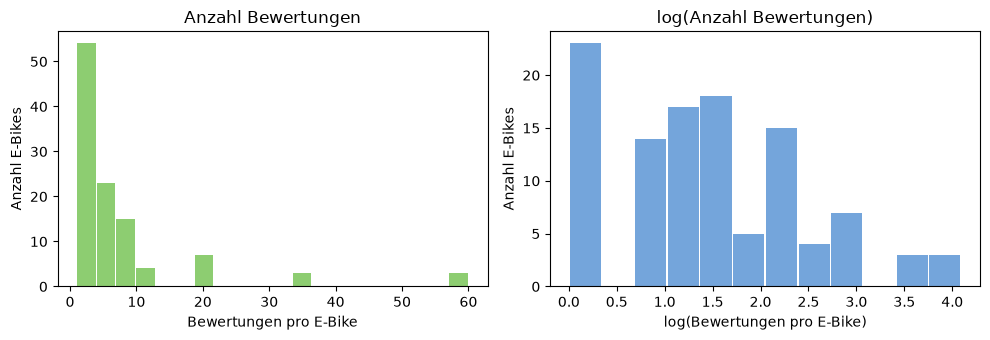

In [8]:
# Read the reviews and count the reviews per e-bike
df_reviews = pd.read_json('reviews.json')
df_counts = df_reviews.groupby('product_id').size().reset_index(name='n_reviews')

# Keep only e-bikes of the shop (inner join: bikes with at least one review)
df_C3 = df_clean[['product_id', 'brand', 'model']].merge(df_counts, on='product_id')
print('Anzahl E-Bikes mit Bewertungen:', df_C3.shape[0])

# Log transformation (all counts are >= 1, so the logarithm is defined)
df_C3['log_n_reviews'] = np.log(df_C3['n_reviews'])

# Skewness before and after
print('Schiefe vorher: ', round(df_C3['n_reviews'].skew(), 2))
print('Schiefe nachher:', round(df_C3['log_n_reviews'].skew(), 2))

# Histograms side by side
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df_C3['n_reviews'], bins=20, color='#42AD12', alpha=0.6, rwidth=0.95)
ax[0].set(title='Anzahl Bewertungen', xlabel='Bewertungen pro E-Bike', ylabel='Anzahl E-Bikes')
ax[1].hist(df_C3['log_n_reviews'], bins=12, color='#1769C4', alpha=0.6, rwidth=0.95)
ax[1].set(title='log(Anzahl Bewertungen)', xlabel='log(Bewertungen pro E-Bike)', ylabel='Anzahl E-Bikes')
plt.tight_layout()
plt.show()

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 35–37 (Datentransformation: log, Wurzel, Box-Cox; Box-Cox/log setzen y > 0 voraus); Folien Woche 5, S. 18–19 (Schiefe), S. 31–32 (Histogramm) und S. 43 (`fig, ax = plt.subplots()`); Folien Woche 4 Teil II, S. 49 (`groupby`).*

---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [9]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('-----------------------------------')


-----------------------------------
POSIX
Darwin | 25.5.0
Datetime: 2026-11-05 19:09:05
Python Version: 3.14.4
-----------------------------------
